Training images: 2,567
Test images: 556
Classes: 5 (daisy, dandelion, rose, sunflower, tulip)

Fine-tuning MobileNetV2...
Total parameters: 2,230,277
Trainable parameters: 2,230,277
Model state size: 8.64 MiB (parameters and buffers)
Epoch [01/20] - Train Loss: 0.8887, Train Acc: 67.12%
Epoch [02/20] - Train Loss: 0.4143, Train Acc: 85.78%
Epoch [03/20] - Train Loss: 0.2483, Train Acc: 92.17%
Epoch [04/20] - Train Loss: 0.2193, Train Acc: 92.33%
Epoch [05/20] - Train Loss: 0.1402, Train Acc: 95.64%
Epoch [06/20] - Train Loss: 0.1328, Train Acc: 95.68%
Epoch [07/20] - Train Loss: 0.1535, Train Acc: 95.13%
Epoch [08/20] - Train Loss: 0.0866, Train Acc: 97.43%
Epoch [09/20] - Train Loss: 0.1252, Train Acc: 95.71%
Epoch [10/20] - Train Loss: 0.1253, Train Acc: 95.64%
Epoch [11/20] - Train Loss: 0.1045, Train Acc: 96.69%
Epoch [12/20] - Train Loss: 0.0708, Train Acc: 97.55%
Epoch [13/20] - Train Loss: 0.0524, Train Acc: 98.29%
Epoch [14/20] - Train Loss: 0.0860, Train Acc: 97.20%
Epoch [15/

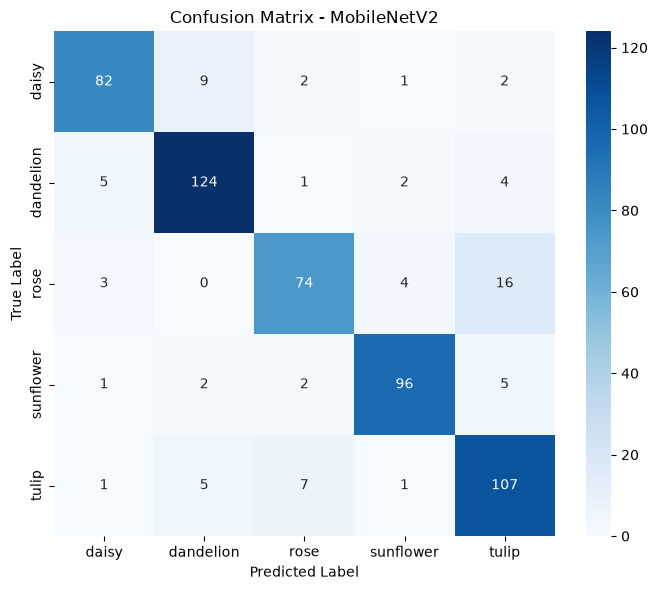


Fine-tuning EfficientNet-B0...
Total parameters: 4,013,953
Trainable parameters: 4,013,953
Model state size: 15.47 MiB (parameters and buffers)
Epoch [01/20] - Train Loss: 0.9417, Train Acc: 64.04%
Epoch [02/20] - Train Loss: 0.4333, Train Acc: 84.57%
Epoch [03/20] - Train Loss: 0.2788, Train Acc: 90.81%
Epoch [04/20] - Train Loss: 0.2394, Train Acc: 91.74%
Epoch [05/20] - Train Loss: 0.2147, Train Acc: 92.79%
Epoch [06/20] - Train Loss: 0.1710, Train Acc: 94.20%
Epoch [07/20] - Train Loss: 0.1487, Train Acc: 95.21%
Epoch [08/20] - Train Loss: 0.1337, Train Acc: 95.44%
Epoch [09/20] - Train Loss: 0.1206, Train Acc: 96.07%
Epoch [10/20] - Train Loss: 0.1302, Train Acc: 95.95%
Epoch [11/20] - Train Loss: 0.1014, Train Acc: 96.88%
Epoch [12/20] - Train Loss: 0.0684, Train Acc: 97.78%
Epoch [13/20] - Train Loss: 0.1190, Train Acc: 96.57%
Epoch [14/20] - Train Loss: 0.1111, Train Acc: 96.46%
Epoch [15/20] - Train Loss: 0.0727, Train Acc: 97.78%
Epoch [16/20] - Train Loss: 0.1116, Train Acc

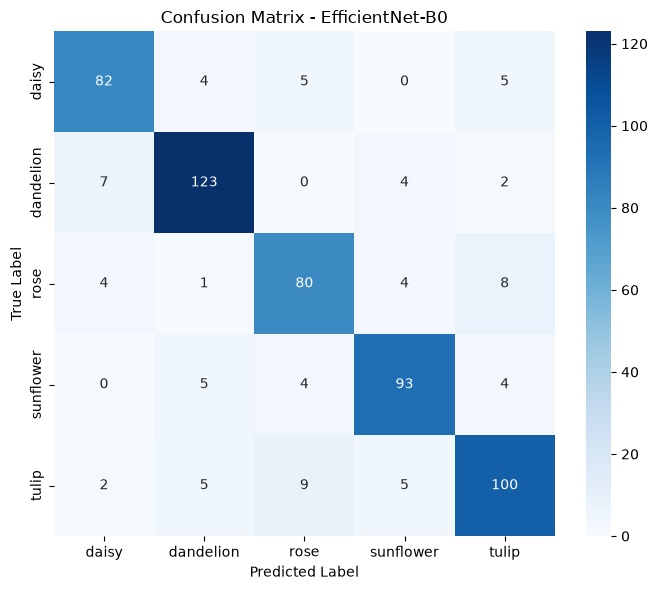

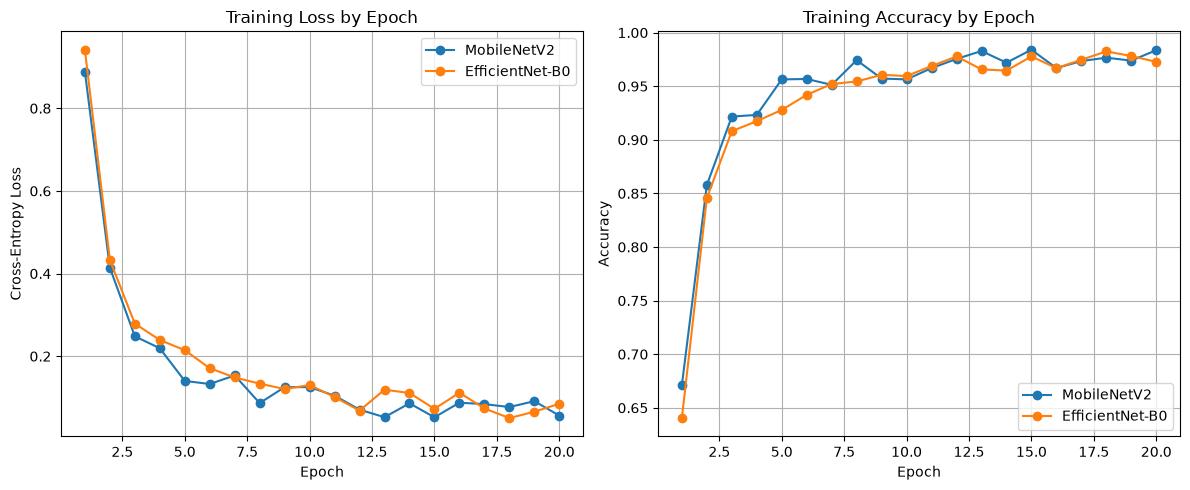

In [2]:
import os
import sys
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
#import models.sota_models as sota_models

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from models.sota_models import get_mobilenet_v2, get_efficientnet_b0
from utils.metrics import compute_and_plot_metrics

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

TRAIN_DIR = os.path.join(PROJECT_ROOT, "data", "train")
TEST_DIR = os.path.join(PROJECT_ROOT, "data", "test")

train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=transform)
test_dataset = datasets.ImageFolder(root=TEST_DIR, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
class_names = train_dataset.classes

print(f"Training images: {len(train_dataset):,}")
print(f"Test images: {len(test_dataset):,}")
print(f"Classes: {len(class_names)} ({', '.join(class_names)})")

sota_models = {
    'MobileNetV2': get_mobilenet_v2(num_classes=5),
    'EfficientNet-B0': get_efficientnet_b0(num_classes=5)
}

criterion = nn.CrossEntropyLoss()
training_history = {}

for name, model in sota_models.items():
    total_parameters = sum(parameter.numel() for parameter in model.parameters())
    trainable_parameters = sum(
        parameter.numel() for parameter in model.parameters() if parameter.requires_grad
    )
    model_size_bytes = sum(
        tensor.numel() * tensor.element_size() for tensor in model.state_dict().values()
    )
    model_size_mib = model_size_bytes / (1024 ** 2)

    print(f"\nFine-tuning {name}...")
    print(f"Total parameters: {total_parameters:,}")
    print(f"Trainable parameters: {trainable_parameters:,}")
    print(f"Model state size: {model_size_mib:.2f} MiB (parameters and buffers)")
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.0005) # Lower LR for fine-tuning
    training_history[name] = {"loss": [], "accuracy": []}
    
    # Train for 20 epochs
    for epoch in range(20):
        model.train()
        running_loss = 0.0
        correct_predictions = 0
        examples_seen = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            correct_predictions += (outputs.argmax(dim=1) == labels).sum().item()
            examples_seen += batch_size

        epoch_loss = running_loss / examples_seen
        epoch_accuracy = correct_predictions / examples_seen
        training_history[name]["loss"].append(epoch_loss)
        training_history[name]["accuracy"].append(epoch_accuracy)
        print(
            f"Epoch [{epoch + 1:02d}/20] - "
            f"Train Loss: {epoch_loss:.4f}, "
            f"Train Acc: {epoch_accuracy:.2%}"
        )

    # Test Evaluation
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    # Compute Metrics
    compute_and_plot_metrics(all_labels, all_preds, class_names, model_name=name)

# Plot training loss and accuracy as the epochs progress.
epochs = range(1, 21)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, history in training_history.items():
    axes[0].plot(epochs, history["loss"], marker="o", label=name)
    axes[1].plot(epochs, history["accuracy"], marker="o", label=name)

axes[0].set(title="Training Loss by Epoch", xlabel="Epoch", ylabel="Cross-Entropy Loss")
axes[1].set(title="Training Accuracy by Epoch", xlabel="Epoch", ylabel="Accuracy")
for axis in axes:
    axis.grid(True)
    axis.legend()
fig.tight_layout()
fig.savefig("sota_training_curves.png")
plt.show()